# Econ 4850 · Economic Analysis with Python
## Lecture 6: Plotting
Geoffrey Kam, Washington University in St. Louis · g.kam@wustl.edu · Spring 2025

**What you'll learn**

- Where to start with the three most common Python plotting libraries: Matplotlib, Plotly and Seaborn.
- How to explore a well-structured dataset in one command with `sns.pairplot`.
- How to customize a grid of pairwise plots with `sns.PairGrid`.

## Overview

This will be a quick one. I introduce three libraries, skip the first two, and quickly highlight the plot that changed how I do research.

- For pandas, you should still know the basic syntax, because you should always fully understand how your data are manipulated.
- With generative AI, you can always ask it to make the plot for you.
- I just want to share three commonly used libraries. You can go over their tutorials quickly by yourself.

1. [Matplotlib](https://matplotlib.org/stable/tutorials/index.html#tutorials)
    - This is the basic way to quickly plot things.
    - Please read at least [this tutorial](https://matplotlib.org/stable/tutorials/lifecycle.html#sphx-glr-tutorials-lifecycle-py); it covers most of what you need.

2. [Plotly](https://plotly.com/python/)
    - It makes fancy-looking plots with interactive features.
    - As a researcher, I never use it.
    - As an RA, I used it to make it look as if I had put a lot of time into the project.
    - In Lecture 5, I showed you the only command you need (`px.line`).

3. [Seaborn](https://seaborn.pydata.org/tutorial.html)
    - It is less well known, but it is great.
    - It is worth your time to go over what it can do once.
    - If you have a well-structured dataset, you should always use it.
    - It focuses on visualizing statistical patterns in the data.

## Seaborn: `pairplot`

We use seaborn's example dataset on penguins.

In [1]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 500)
pd.set_option("display.max_rows", 100)

# Load the example dataset
df = sns.load_dataset("penguins")

In [2]:
df

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
...,...,...,...,...,...,...,...
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,Female
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female


In [3]:
df.describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


`sns.pairplot` plots every pair of numeric variables against each other, with the distribution of each variable on the diagonal.

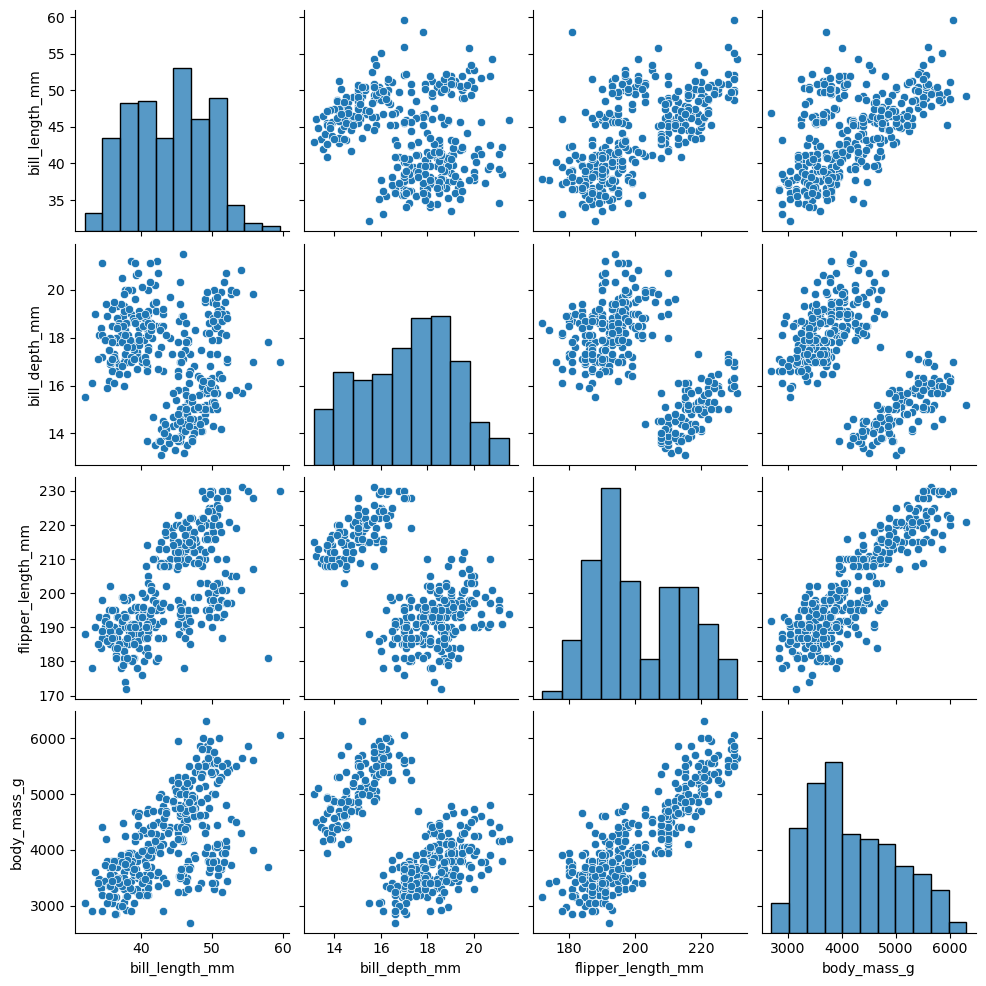

In [4]:
sns.pairplot(df)

Use `vars` to choose which columns to include. First, list the column names:

In [5]:
df.columns

Index(['species', 'island', 'bill_length_mm', 'bill_depth_mm',
       'flipper_length_mm', 'body_mass_g', 'sex'],
      dtype='object')

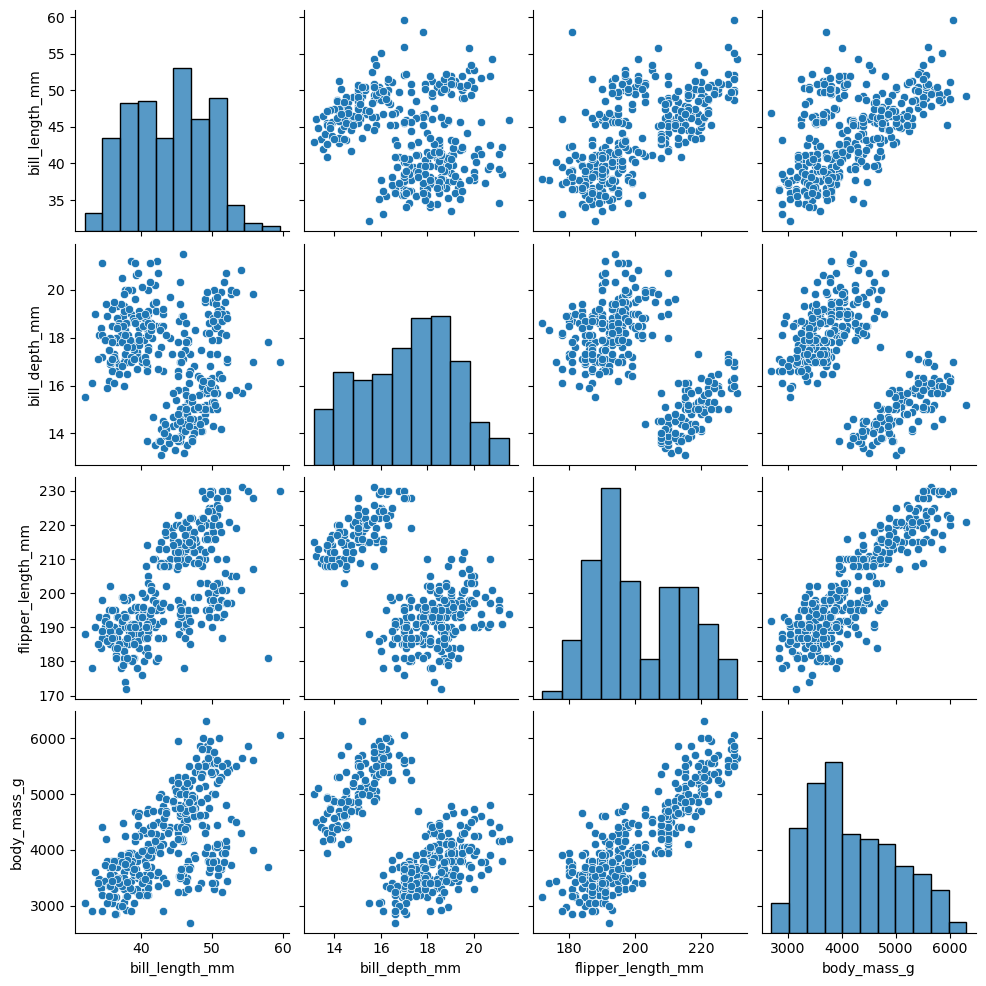

In [6]:
sns.pairplot(df,
             vars=["bill_length_mm", "bill_depth_mm",
                   "flipper_length_mm", "body_mass_g"])

`hue` colors the observations by a categorical variable, here the species:

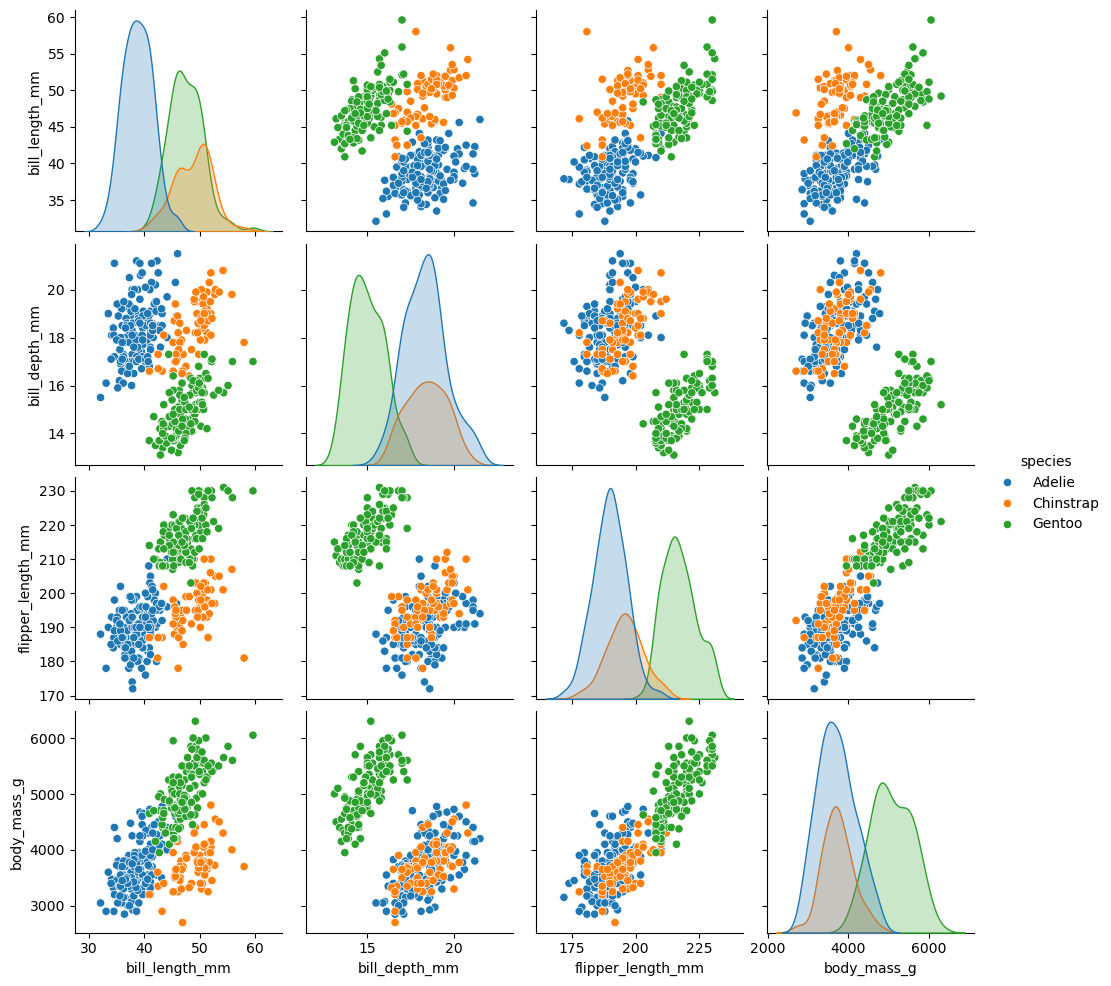

In [7]:
sns.pairplot(df,
             vars=["bill_length_mm", "bill_depth_mm",
                   "flipper_length_mm", "body_mass_g"],
             hue="species")

or by sex:

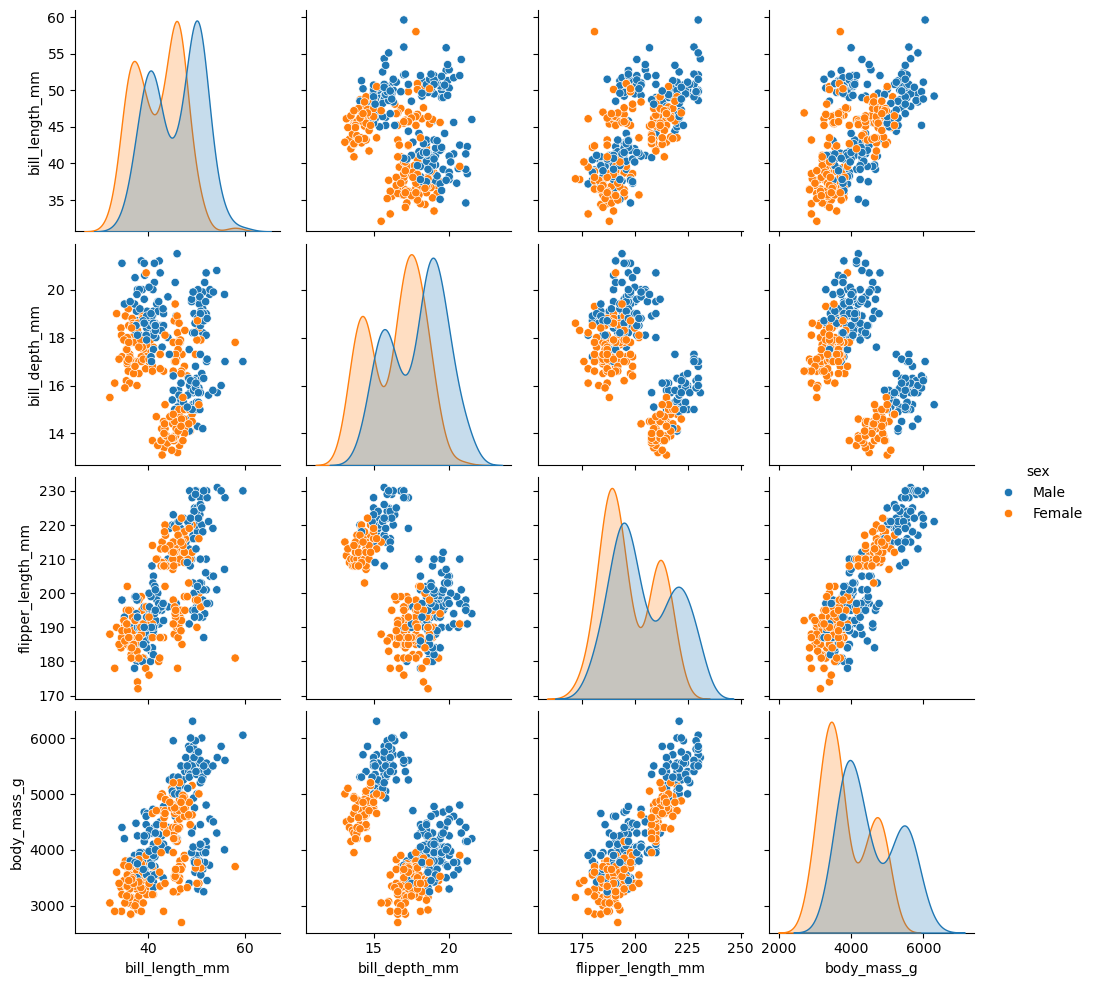

In [8]:
sns.pairplot(df,
             vars=["bill_length_mm", "bill_depth_mm",
                   "flipper_length_mm", "body_mass_g"],
             hue="sex")

`kind="reg"` adds a linear regression fit to each scatter plot:

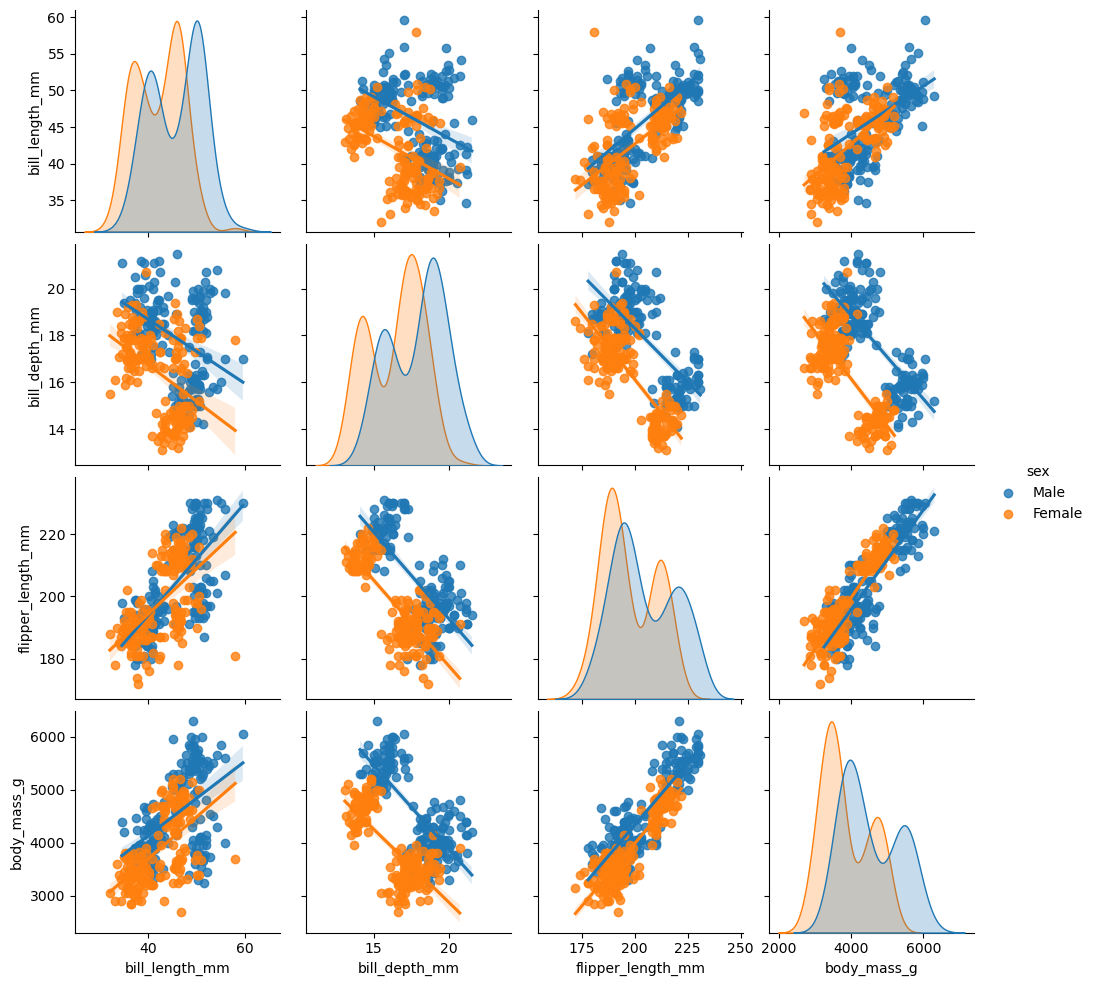

In [9]:
sns.pairplot(df,
             vars=["bill_length_mm", "bill_depth_mm",
                   "flipper_length_mm", "body_mass_g"],
             hue="sex",
             kind="reg")

## Seaborn: `PairGrid`

If you want to customize the plot, use `PairGrid`, which lets you choose a different plot for the lower triangle, the upper triangle and the diagonal. (For a nonparametric fit instead of a linear one, you can pass `lowess=True` to `sns.regplot`; this requires the `statsmodels` package.)

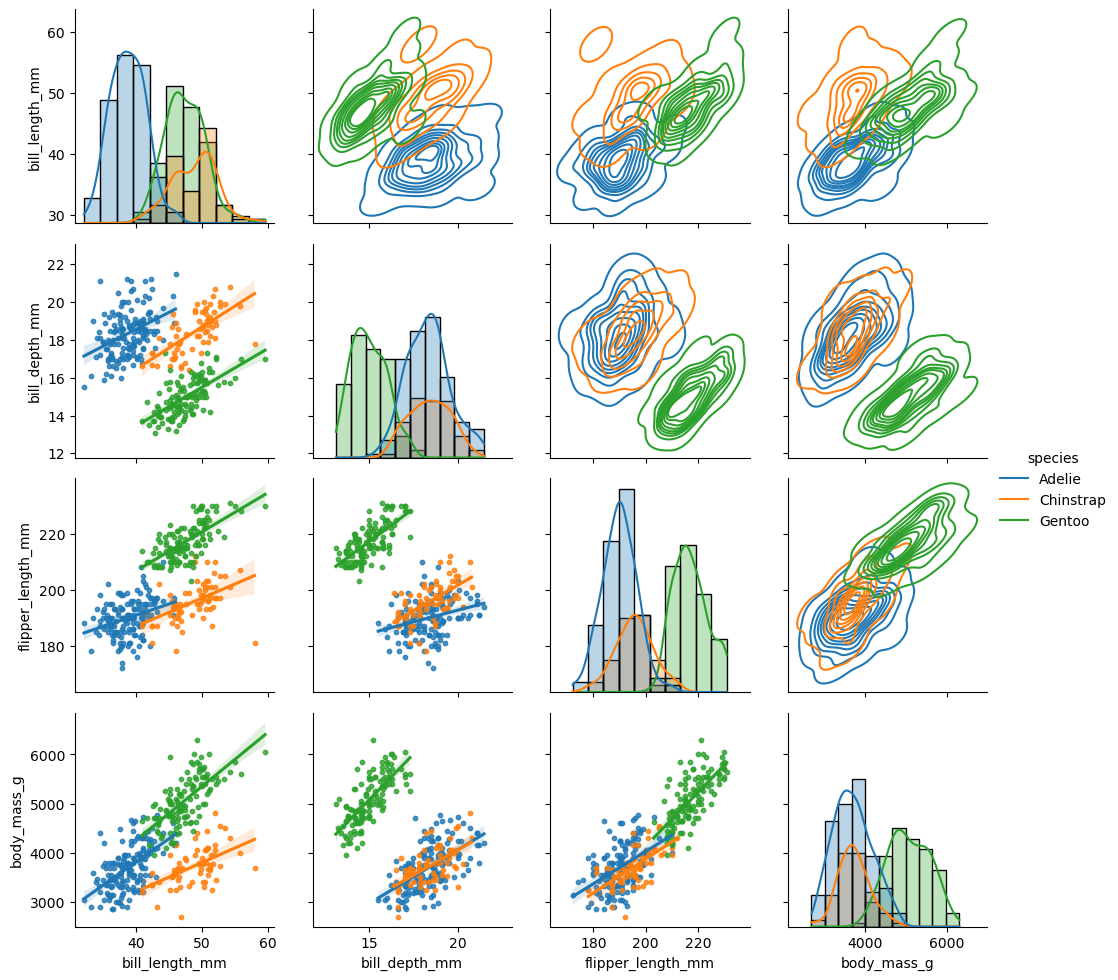

In [10]:
# Initialize the PairGrid
g = sns.PairGrid(df, vars=["bill_length_mm", "bill_depth_mm",
                           "flipper_length_mm", "body_mass_g"], hue="species")

# Lower triangle: regression plots
g.map_lower(sns.regplot, scatter_kws={"s": 10})

# Upper triangle: KDE plots
g.map_upper(sns.kdeplot, thresh=0.005)

# Diagonal: histogram with a KDE
g.map_diag(sns.histplot, kde=True, alpha=0.3)

g.add_legend()

plt.show()

The same grid without `hue`, pooling all species:

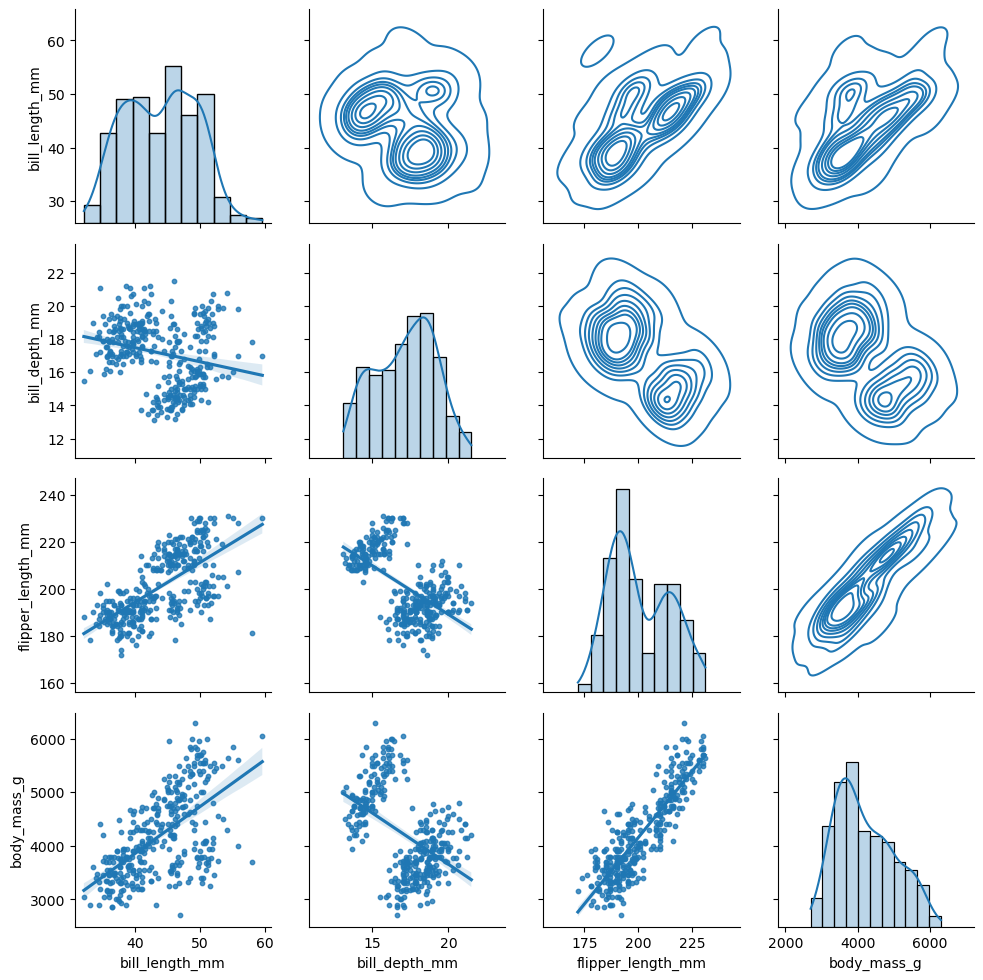

In [11]:
g = sns.PairGrid(df, vars=["bill_length_mm", "bill_depth_mm",
                           "flipper_length_mm", "body_mass_g"])

# Lower triangle: regression plots
g.map_lower(sns.regplot, scatter_kws={"s": 10})

# Upper triangle: KDE plots
g.map_upper(sns.kdeplot, thresh=0.005)

# Diagonal: histogram with a KDE
g.map_diag(sns.histplot, kde=True, alpha=0.3)

plt.show()